# 05 Validation against the USGS creepmeters, and the aperture choice

```
Created on Mon Sep 21 2026
@author: daniellelindsay
Run in opera_disp_feb13. The bootstraps take ~2 min; the ladder scoring reads
the frozen sweep directories and takes ~1 min.
```

**What this notebook does.** It compares the InSAR creep with the five USGS
creepmeters over the same window, three ways, all from the same stacked
time series (Methods M4):

- **creepmeter**: the instrument's own rate (ground truth, already fault-parallel)
- **crossing**: the InSAR fault-parallel creep rate from `fp_ts.csv` (notebook 03),
  the narrow-aperture like-for-like match to a point instrument
- **step**: the fault-crossing step in the fault-parallel velocity field
  (notebook 02 transects, +/-1000 m), which also carries the distributed part

Every rate uncertainty is a moving-block bootstrap 95% confidence interval
(blocks of ~1 yr in time, ~100 m in distance), because both the time series
and the profiles are autocorrelated and an ordinary standard error would be
2 to 3 times too small. The detrended comparison gives the transient noise
floor that the event detector (05) needs.

The second part draws the **aperture ladder**: why the creep time series use
the 30 to 150 m bin. The sweep itself was run once in July/August 2026
(`Hayward_DISP-S1/analysis/run11b_sweep_ladder.py`); its outputs are read
here as frozen inputs (fingerprinted in the registry) and re-scored on a
fixed stack. It is not re-run (Dani, 2026-09-21).

Ported from `Hayward_DISP-S1/analysis/run10_creepmeter_validation.py`,
`plotting/fig_validation.py` and `plotting/figS_binning_ladder.py`.

**Outputs** (`outputs/05_validation/`): `station_agreement.csv`,
`sweep_ladder_scores.csv`, `04_validation_stats.txt`, registry rows `05_*`.

**Figures**: the five-station validation figure (supplement) and the ladder.

**What to check.** CFW1, CTM1 and CPP1 should agree with the creepmeters to a
few tenths of a millimetre a year; COZ1 is the known low outlier (the InSAR
recovers only part of its two large creep events); CHP1 runs high because
its creep is distributed over ~300 m. The detrended RMSE per station (~1.6 to
1.8 mm) is the single-crossing noise floor quoted in the text.

In [1]:
import os
import json
import warnings

import insar_utils as utils
from TulePond_filepaths import (common_paths, creepmeters, segments, params, x_width,
                                dist_min, dist_max, coh_timeseries, min_points, coh_velocity,
                                paths_out, repo_dir)

import numpy as np
import pandas as pd
import h5py
import pyproj
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import pygmt

## Constants

In [2]:
notebook = "05_validation"
out_dir = paths_out[notebook]
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

block_years = 1.0     # moving-block length for the time bootstraps (carries the annual cycle)
block_m = 100.0       # moving-block length (m) for the spatial step bootstrap
nboot = 2000          # bootstrap resamples
seed = 0
stack_km = 0.2        # half-window of fp_ts rows to stack at a creepmeter (matches the 400 m swath)
stack_widen_km = 1.0  # widen to this if the 0.2 km window has < 2 usable rows (CPP1 at the frame edge)
stack_max = 5         # cap the stack at the N nearest usable rows
swath_m, max_dist_m = 200.0, 1000.0   # the notebook 02 transects
strike = 144.0        # page rotation of the map panel (mean strike, notebook 02)
map_half_km = 10.0    # map panel cross-fault half-width
ref_patch_km = 5.0    # map display reference: CTM1-COZ1 patch, +/- this across the fault

# the COZ1 creep events the creepmeter recorded, used to score how much of the
# step each aperture recovers (ladder panel d); windows from the creepmeter record
coz1_events = [(2018.997, 2019.121), (2022.093, 2022.219)]
collar_yr = 0.75      # inter-event collar each side of a window for the local trend

# CFW1 vs the Tule Pond InSAR events (the instrument sits at the south end of the section). This notebook
# only MEASURES the creepmeter slip across each InSAR detection window, from the raw record and aware of
# its gaps; whether CFW1 recorded a creep event is a question for the published catalogue (TBC), not for a
# detector written here.
cfw_edge_hours = 12   # slip across a window = median of the samples in the last 12 h before it closes minus
                      # the median in the first 12 h after it opens (nearest available samples if those are in a gap)

# the ladder: bins scored on a FIXED stack (4 rows within 0.4 km, no widening)
# so every bin averages the same number of rows. The sweep was run at coherence
# 0.9; the three-threshold comparison of the chosen bin (below) is what justifies
# running the paper's stream at 0.7.
ladder_coh = 0.9
ladder_stack_km, ladder_n_stack = 0.4, 4
fixed_width = [(0, 100), (50, 150), (100, 200), (150, 250), (200, 300), (300, 400), (400, 500)]
growing = [(100, 200), (100, 300), (100, 400), (100, 500), (100, 700)]
original = [(0, 60), (30, 90), (60, 120), (0, 120), (30, 150), (60, 180), (200, 600), (500, 700)]
inner_edge = [(0, 150), (10, 150), (20, 150), (30, 150), (40, 150), (50, 150), (60, 150), (70, 150), (80, 150)]
selected = (int(dist_min * 1000), int(dist_max * 1000))      # the bin the paper uses
kernel_m = (55, 65)   # measured DISP-S1 phase-linking half-width, before / after the 2024-25 reprocessing

fp_ts_file = os.path.join(paths_out["03_creep_timeseries"], "fp_ts.csv")
xf_file = os.path.join(paths_out["02_velocity_decomposition"], f"fp_velocity_xfault_swath{swath_m:.0f}m_dist{max_dist_m:.0f}m.csv")
map_file = os.path.join(paths_out["02_velocity_decomposition"], "fp_velocity_map.h5")
events_file = os.path.join(paths_out["04_event_detection"], "creep_events.csv")
lengths_file = os.path.join(paths_out["04_event_detection"], "section_lengths.csv")   # the measured section extents

REG = utils.Registry(notebook, common_paths, repo_dir)
REG.inputs(fp_ts_file, xf_file, map_file, lengths_file, events_file, common_paths["fault_profiles"],
           *[utils.creepmeter_file(common_paths["creepmeter_dir"], c[0]) for c in creepmeters],
           os.path.join(common_paths["sweep_dir"], "sweep_summary_ladder_coh0.9_mp5.csv"))

Registry for 05_validation: run 9a7639e3, git 2d8c610+


## LOAD: the creep time series, the transects and the creepmeters

The creepmeter records are daily means over the InSAR window with gross
glitches removed (a robust filter; CPP1 has spikes to -338 mm). The InSAR
"stack" at a creepmeter is the mean of the nearest usable `fp_ts` rows within
200 m along strike (up to 5 rows), which is the like-for-like match to the
400 m transect swath.

In [3]:
fp_ts = pd.read_csv(fp_ts_file, index_col=0)
fp_ts.columns = fp_ts.columns.astype(float)
fp_ts.index = fp_ts.index.astype(float)
t0, t1 = float(fp_ts.columns.min()), float(fp_ts.columns.max())
xf = pd.read_csv(xf_file)
print(f"fp_ts: {fp_ts.shape[0]} crossings x {fp_ts.shape[1]} epochs, window {t0:.3f} to {t1:.3f} ({t1 - t0:.2f} yr)")
print(f"transects: {len(xf)} pixels at {xf.code.nunique()} creepmeters")


def daily_creepmeter(code):
    """Creepmeter cumulative slip over the InSAR window, glitch-filtered and daily-averaged."""
    cm = utils.read_creepmeter_10min(utils.creepmeter_file(common_paths["creepmeter_dir"], code),
                                     date_start=t0, date_end=t1)
    sl = cm["slip_mm"].values
    med = np.median(sl)
    mad = np.median(np.abs(sl - med)) or 1.0
    cm = cm[np.abs(sl - med) < 6 * 1.4826 * mad + 10].reset_index(drop=True)
    return cm["decimal_year"].values, cm["slip_mm"].values - cm["slip_mm"].values[0]


def stack_insar(fp, lat, half_km=stack_km, widen_km=stack_widen_km, n_stack=stack_max, exact=False):
    """Mean +/- std of the fp_ts rows nearest `lat`. `exact=True` (the ladder)
    requires n_stack usable rows inside half_km and never widens, so every bin
    is scored on the same number of rows. Returns (t, mean, std, n) or None."""
    nepoch = fp.shape[1]
    for km in ((half_km,) if exact else (half_km, widen_km)):
        dlat = km / 111.19
        sub = fp[(fp.index >= lat - dlat) & (fp.index <= lat + dlat)]
        usable = sub[sub.notna().sum(axis=1) > 0.5 * nepoch]
        if len(usable) >= 2:
            break
    if len(usable) == 0 or (exact and len(usable) < n_stack):
        return None
    usable = usable.iloc[np.argsort(np.abs(usable.index.values - lat))[:n_stack]]
    t = fp.columns.values.astype(float)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        return t, np.nanmean(usable.values, axis=0), np.nanstd(usable.values, axis=0), len(usable)


cm_data = {code: daily_creepmeter(code) for code, la, lo, name in creepmeters}
for code, la, lo, name in creepmeters:
    ct, ccum = cm_data[code]
    st = stack_insar(fp_ts, la)
    print(f"  {code} ({name}): creepmeter {len(ct)} days, {ccum[-1]:.1f} mm total; InSAR stack of {st[3] if st else 0} rows")

fp_ts: 610 crossings x 439 epochs, window 2016.672 to 2026.216 (9.54 yr)
transects: 3621 pixels at 5 creepmeters


  CPP1 (Pinole Point): creepmeter 3420 days, 48.8 mm total; InSAR stack of 4 rows
  CTM1 (Temescal): creepmeter 3225 days, 39.9 mm total; InSAR stack of 5 rows
  COZ1 (Oakland Zoo): creepmeter 3484 days, 39.8 mm total; InSAR stack of 5 rows
  CHP1 (Palisade Street): creepmeter 3353 days, 37.2 mm total; InSAR stack of 5 rows
  CFW1 (Fremont): creepmeter 3437 days, 67.2 mm total; InSAR stack of 5 rows


## RUN: rates with bootstrap confidence intervals

Per station: the creepmeter rate, the crossing rate and the velocity-field
step, each with a moving-block bootstrap 95% CI (residuals resampled in
contiguous blocks, re-added to the fitted trend, refitted). Then the
cumulative misfit, and the detrended comparison: the correlation of the two
detrended series (does the InSAR see the same transients?) and the detrended
RMSE (the single-station noise floor).

In [4]:
rng = np.random.default_rng(seed)


def slope(t, y):
    """OLS slope in closed form, so the bootstrap refit is fast."""
    tc = t - t.mean()
    return float(tc @ (y - y.mean()) / (tc @ tc))


def block_bootstrap_slope(x, y, block_len):
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)
    b = np.polyfit(x, y, 1)
    trend = np.polyval(b, x); resid = y - trend
    block_len = int(max(2, min(block_len, n)))
    n_blocks = int(np.ceil(n / block_len))
    out = np.empty(nboot)
    for k in range(nboot):
        starts = rng.integers(0, n - block_len + 1, size=n_blocks)
        idx = np.concatenate([np.arange(s, s + block_len) for s in starts])[:n]
        out[k] = slope(x, trend + resid[idx])
    return b[0], np.percentile(out, 2.5), np.percentile(out, 97.5)


def step_fit(d, v):
    """v = a + b*d + step*[d > 0]; the step is the fault-crossing creep rate."""
    G = np.column_stack([np.ones_like(d), d, (d > 0).astype(float)])
    a, b, step = np.linalg.lstsq(G, v, rcond=None)[0]
    return step, a + b * d + step * (d > 0)


def block_bootstrap_step(d, v):
    order = np.argsort(d); d, v = d[order], v[order]
    step0, pred = step_fit(d, v)
    resid = v - pred
    block_len = int(max(3, round(len(d) * block_m / (d.max() - d.min()))))
    n = len(d); n_blocks = int(np.ceil(n / block_len))
    out = np.empty(nboot)
    for k in range(nboot):
        starts = rng.integers(0, n - block_len + 1, size=n_blocks)
        idx = np.concatenate([np.arange(s, s + block_len) for s in starts])[:n]
        out[k], _ = step_fit(d, pred + resid[idx])
    return step0, np.percentile(out, 2.5), np.percentile(out, 97.5)


def largest_event(t, cum, win_days=60.0):
    """Largest rise in cumulative slip over any window up to win_days."""
    win = win_days / 365.25
    best = 0.0
    for i in range(0, len(t), 50):
        j = np.searchsorted(t, t[i] + win)
        if j < len(t):
            best = max(best, cum[j] - cum[i])
    return best


def n_eff(x):
    """Effective sample size under lag-1 autocorrelation."""
    x = x[np.isfinite(x)]; xm = x - x.mean()
    r1 = float(xm[1:] @ xm[:-1] / (xm @ xm))
    return len(x) * (1 - r1) / (1 + r1), r1


rows = []
for code, la, lo, name in creepmeters:
    ct, ccum = cm_data[code]
    dt = np.median(np.diff(ct))
    cm_rate, cm_lo, cm_hi = block_bootstrap_slope(ct, ccum, round(block_years / dt))
    t, mean, std, nstack = stack_insar(fp_ts, la)
    ok = np.isfinite(mean); ti, ins = t[ok], mean[ok]
    cr_rate, cr_lo, cr_hi = block_bootstrap_slope(ti, ins, round(block_years / np.median(np.diff(ti))))
    s = xf[(xf["code"] == code) & (xf["dist_m"].abs() <= max_dist_m)]
    st_rate, st_lo, st_hi = block_bootstrap_step(s["dist_m"].values.astype(float), s["fp_vel"].values.astype(float))
    cmi = np.interp(ti, ct, ccum)                      # creepmeter ON the SAR epochs
    res = ins - cmi
    di, dc = utils.detrend(ti, ins), utils.detrend(ti, cmi)
    gd = np.isfinite(di) & np.isfinite(dc)
    neff, r1 = n_eff(di[gd])
    rows.append(dict(code=code, name=name, nstack=nstack, nepoch=int(ok.sum()),
                     cm_rate=cm_rate, cm_lo=cm_lo, cm_hi=cm_hi, cr_rate=cr_rate, cr_lo=cr_lo, cr_hi=cr_hi,
                     st_rate=st_rate, st_lo=st_lo, st_hi=st_hi,
                     d_cross=cr_rate - cm_rate, d_step=st_rate - cm_rate, distributed=st_rate - cr_rate,
                     sig_cross=np.hypot((cr_hi - cr_lo) / 3.92, (cm_hi - cm_lo) / 3.92),
                     sig_step=np.hypot((st_hi - st_lo) / 3.92, (cm_hi - cm_lo) / 3.92),
                     cum_rmse=np.sqrt(np.mean(res ** 2)), cum_mad=1.4826 * np.median(np.abs(res - np.median(res))),
                     det_std_ins=np.nanstd(di), det_std_cm=np.nanstd(dc),
                     det_rmse=float(np.sqrt(np.mean((di[gd] - dc[gd]) ** 2))),
                     event_cm=largest_event(ct, ccum), det_r=float(np.corrcoef(di[gd], dc[gd])[0, 1]),
                     det_r1=r1, det_neff=neff))
    print(f"  {code}: creepmeter {cm_rate:5.2f} [{cm_lo:.2f}, {cm_hi:.2f}]  crossing {cr_rate:5.2f} [{cr_lo:.2f}, {cr_hi:.2f}]  "
          f"step {st_rate:5.2f} [{st_lo:.2f}, {st_hi:.2f}]  det r {rows[-1]['det_r']:.2f}  det RMSE {rows[-1]['det_rmse']:.2f} mm")
df = pd.DataFrame(rows).set_index("code")
df.to_csv(os.path.join(out_dir, "station_agreement.csv"))

  CPP1: creepmeter  5.05 [4.95, 5.14]  crossing  5.07 [4.81, 5.36]  step  3.65 [2.48, 4.76]  det r 0.27  det RMSE 1.83 mm


  CTM1: creepmeter  4.11 [4.02, 4.21]  crossing  4.20 [3.92, 4.49]  step  3.77 [3.29, 4.20]  det r 0.37  det RMSE 1.89 mm


  COZ1: creepmeter  4.43 [4.12, 4.75]  crossing  3.06 [2.82, 3.27]  step  3.09 [2.58, 3.61]  det r 0.58  det RMSE 1.66 mm


  CHP1: creepmeter  3.81 [3.75, 3.86]  crossing  4.20 [4.08, 4.32]  step  4.95 [4.31, 5.59]  det r -0.22  det RMSE 1.63 mm


  CFW1: creepmeter  6.99 [6.77, 7.21]  crossing  6.55 [6.43, 6.66]  step  6.58 [6.14, 7.03]  det r 0.33  det RMSE 1.49 mm


## Ensemble agreement and the noise floor

Agreement is reported three ways because no single number suffices: rate
residual statistics (bias, RMS, reduced chi-square against the combined
CI), the same excluding COZ1, and the detrended RMSE. Two noise-floor
definitions are printed side by side; the text quotes the mean detrended
RMSE (~1.7 mm at a single crossing).

In [5]:
def agreement(sub, key):
    delta = sub[f"d_{key}"].values; sig = sub[f"sig_{key}"].values
    w = 1.0 / sig ** 2; bias = np.mean(delta); sd = np.std(delta, ddof=1)
    return dict(bias=bias, median_bias=np.median(delta), wrms=np.sqrt(np.sum(w * delta ** 2) / np.sum(w)),
                rms=np.sqrt(np.mean(delta ** 2)), chi2v=np.mean((delta / sig) ** 2),
                ba_lo=bias - 1.96 * sd, ba_hi=bias + 1.96 * sd, maxabs=np.max(np.abs(delta)))


agr = {"cross": agreement(df, "cross"), "step": agreement(df, "step"),
       "cross_excl_coz1": agreement(df.drop("COZ1"), "cross")}
steady = df[df.det_std_cm < 1.0]                 # stations whose creepmeter transient is sub-mm
floor_run10 = float(steady.det_std_ins.median())  # there the detrended InSAR is pure epoch noise
floor_rmse = float(df.det_rmse.mean())

L = ["=" * 78, "CREEPMETER vs INSAR: CREEP-RATE AGREEMENT", "=" * 78,
     f"InSAR window {t0:.3f} to {t1:.3f} ({t1 - t0:.2f} yr); creep bin {dist_min * 1000:.0f}-{dist_max * 1000:.0f} m, "
     f"along-strike +/-{x_width * 1000:.0f} m, coherence {coh_timeseries}",
     f"velocity-field step: +/-{max_dist_m:.0f} m transects, swath +/-{swath_m:.0f} m; InSAR stack <= {stack_max} rows within +/-{stack_km * 1000:.0f} m",
     f"bootstrap: {nboot} moving-block resamples (block ~{block_years:g} yr / {block_m:.0f} m), seed {seed}", "",
     "PER-STATION RATES (mm/yr) [95% CI]",
     f"{'code':5} {'creepmeter':>22} {'crossing':>22} {'step':>22}"]
for c, r in df.iterrows():
    L.append(f"{c:5} {r.cm_rate:6.2f} [{r.cm_lo:5.2f},{r.cm_hi:5.2f}]   {r.cr_rate:6.2f} [{r.cr_lo:5.2f},{r.cr_hi:5.2f}]   "
             f"{r.st_rate:6.2f} [{r.st_lo:5.2f},{r.st_hi:5.2f}]")
L += ["", "DIFFERENCES vs CREEPMETER (mm/yr)", f"{'code':5} {'crossing-cm':>12} {'step-cm':>10} {'step-crossing':>14}"]
for c, r in df.iterrows():
    L.append(f"{c:5} {r.d_cross:12.2f} {r.d_step:10.2f} {r.distributed:14.2f}")
L += ["", "TIME-SERIES AGREEMENT (creepmeter aligned to the InSAR epochs)",
      f"{'code':5} {'cum RMSE':>9} {'det.std ins/cm':>16} {'det.r':>7} {'det RMSE':>9} {'N_eff':>7} {'N_ep':>5}"]
for c, r in df.iterrows():
    L.append(f"{c:5} {r.cum_rmse:9.2f} {r.det_std_ins:7.2f}/{r.det_std_cm:<7.2f} {r.det_r:7.2f} {r.det_rmse:9.2f} {r.det_neff:7.0f} {r.nepoch:5d}")
L += ["", "ENSEMBLE AGREEMENT"]
for key, lab in (("cross", "crossing vs creepmeter, all 5"), ("cross_excl_coz1", "crossing vs creepmeter, excl COZ1"),
                 ("step", "velocity step vs creepmeter, all 5")):
    a = agr[key]
    L += [f"{lab}: bias {a['bias']:+.2f} (median {a['median_bias']:+.2f}), RMS {a['rms']:.2f}, weighted RMS {a['wrms']:.2f}, "
          f"max |diff| {a['maxabs']:.2f} mm/yr, reduced chi2 {a['chi2v']:.2f}, Bland-Altman [{a['ba_lo']:+.2f}, {a['ba_hi']:+.2f}]"]
L += ["", "NOISE FLOOR",
      f"median detrended InSAR std at steady stations (creepmeter transient < 1 mm): {floor_run10:.2f} mm",
      f"mean detrended RMSE, InSAR minus creepmeter, all 5: {floor_rmse:.2f} mm (range {df.det_rmse.min():.2f} to {df.det_rmse.max():.2f})"]
print("\n".join(L))

CREEPMETER vs INSAR: CREEP-RATE AGREEMENT
InSAR window 2016.672 to 2026.216 (9.54 yr); creep bin 30-150 m, along-strike +/-200 m, coherence 0.7
velocity-field step: +/-1000 m transects, swath +/-200 m; InSAR stack <= 5 rows within +/-200 m
bootstrap: 2000 moving-block resamples (block ~1 yr / 100 m), seed 0

PER-STATION RATES (mm/yr) [95% CI]
code              creepmeter               crossing                   step
CPP1    5.05 [ 4.95, 5.14]     5.07 [ 4.81, 5.36]     3.65 [ 2.48, 4.76]
CTM1    4.11 [ 4.02, 4.21]     4.20 [ 3.92, 4.49]     3.77 [ 3.29, 4.20]
COZ1    4.43 [ 4.12, 4.75]     3.06 [ 2.82, 3.27]     3.09 [ 2.58, 3.61]
CHP1    3.81 [ 3.75, 3.86]     4.20 [ 4.08, 4.32]     4.95 [ 4.31, 5.59]
CFW1    6.99 [ 6.77, 7.21]     6.55 [ 6.43, 6.66]     6.58 [ 6.14, 7.03]

DIFFERENCES vs CREEPMETER (mm/yr)
code   crossing-cm    step-cm  step-crossing
CPP1          0.02      -1.40          -1.42
CTM1          0.09      -0.35          -0.44
COZ1         -1.38      -1.34           0.03


## Figure: the five creepmeters against the InSAR

Column 1: the fault-parallel velocity map, drawn with GMT's oblique Mercator
so the fault runs up the page at the mean strike (the trace stays curved,
north at the top), creepmeters as blue ticks, the Tule Pond section bracketed
(the measured extent from notebook 04). Columns 2 to 4, one row per
creepmeter north to south: the cross-fault velocity profile with its step;
cumulative creep, creepmeter (blue) against InSAR (grey, +/-1 std of the
stacked rows); the same detrended, with the creep-event onset windows in gold
(COZ1: its own creepmeter events; CFW1: the Tule Pond InSAR events).

In [6]:
utils.mpl_paper_style(base=8)          # Helvetica, 8 pt, editable PDF text (the ladder figure below)
cm_blue, insar_grey, gold = "#0b3d91", "gray55", "#F0E442"
fp_clim, prof_ylim = 5.0, 7.0

with h5py.File(map_file, "r") as h:
    fp_map = h["fp_velocity"][:].astype(float)
    attrs = {k: (v.decode() if isinstance(v, bytes) else str(v)) for k, v in h.attrs.items()}
fp_map[fp_map == 0] = np.nan
prof = pd.read_csv(common_paths["fault_profiles"])
utm = pyproj.Transformer.from_crs(4326, int(attrs["EPSG"]), always_xy=True)
fe, fn = utm.transform(prof["ft_lon"].values, prof["ft_lat"].values)
th = np.deg2rad(strike)
ae, an = np.sin(th), np.cos(th); pe, pn = -np.cos(th), np.sin(th)
u_tr = fe * ae + fn * an; v_tr = fe * pe + fn * pn
u_pin = float(u_tr[-1]); v0 = float(np.median(v_tr))


def to_uv(lon, lat):
    e, n = utm.transform(np.asarray(lon, float), np.asarray(lat, float))
    return ((e * pe + n * pn) - v0) / 1000.0, ((e * ae + n * an) - u_pin) / 1000.0


# the map on the rotated frame (v across, u along), nearest-neighbour lookup
u_south = (float(u_tr[0]) - u_pin) / 1000.0
ug = np.arange(-3.5, u_south + 0.6, 0.09); vg = np.arange(-map_half_km, map_half_km + 0.09, 0.09)
V, U = np.meshgrid(vg, ug)
E = (V * 1000.0 + v0) * pe + (U * 1000.0 + u_pin) * ae
N = (V * 1000.0 + v0) * pn + (U * 1000.0 + u_pin) * an
x0, dx = float(attrs["X_FIRST"]), float(attrs["X_STEP"]); y0, dy = float(attrs["Y_FIRST"]), float(attrs["Y_STEP"])
ci = np.round((E - x0) / dx).astype(int); ri = np.round((N - y0) / dy).astype(int)
ok = (ci >= 0) & (ci < fp_map.shape[1]) & (ri >= 0) & (ri < fp_map.shape[0])
ob_z = np.full(U.shape, np.nan); ob_z[ok] = fp_map[ri[ok], ci[ok]]
ob_ext = [float(vg[0]), float(vg[-1]), float(ug[-1]), float(ug[0])]
# display reference, as Fig 1 (notebook 04): the mid-point of the two blocks' medians in the CTM1-COZ1
# patch, so the fault sits at zero and the colour scale swings equally blue (west) and red (east).
# (A plain patch mean is biased toward whichever block has more valid pixels.)
u_cm = {code: to_uv(lo, la)[1] for code, la, lo, name in creepmeters}
lo_u, hi_u = sorted([u_cm["CTM1"], u_cm["COZ1"]])
in_u = (ug >= lo_u) & (ug <= hi_u)
z_west = np.nanmedian(ob_z[np.ix_(in_u, (vg < 0) & (vg >= -ref_patch_km))])
z_east = np.nanmedian(ob_z[np.ix_(in_u, (vg > 0) & (vg <= ref_patch_km))])
ref_mean = 0.5 * (z_west + z_east)
print(f"map display reference: west block {z_west:+.2f}, east block {z_east:+.2f} mm/yr; mid-point {ref_mean:+.2f} removed")

# section bracket: the MEASURED Tule Pond extent from notebook 04 (section_lengths.csv), the length of
# fault hosting the events. Oakland is no longer highlighted in the paper, so it gets no bracket.
sl = pd.read_csv(lengths_file).set_index("name")
seg_ext = {"Tule Pond": (sl.loc["tulepond_creep_length", "lat_lo"], sl.loc["tulepond_creep_length", "lat_hi"])}
print("section brackets (lat):", {k: (round(v[0], 4), round(v[1], 4)) for k, v in seg_ext.items()})
ev_all = pd.read_csv(events_file) if os.path.exists(events_file) else pd.DataFrame()
events_coz = ev_all.query("segment == 'COZ1'") if len(ev_all) else ev_all
# CFW1 sits at the south end of the Tule Pond section: its rows get the Tule Pond onset windows, to see
# whether the instrument catches any InSAR event. The creepmeter STEP at each event (10-min record)
# is measured below, printed and written to the stats file.
events_tp = ev_all.query("segment == 'TULEPOND'") if len(ev_all) else ev_all
row_events = {"COZ1": events_coz, "CFW1": events_tp}

cfw_raw = utils.read_creepmeter_10min_raw(utils.creepmeter_file(common_paths["creepmeter_dir"], "CFW1"), date_start=t0, date_end=t1)
tr, sr = cfw_raw.decimal_year.values, cfw_raw.slip_mm.values
DAY = 1 / 365.25
cfw_rate = df.loc["CFW1", "cm_rate"]           # the instrument's own long-term rate over the InSAR window, mm/yr


def cfw_level(t_edge, side):
    """Median slip in the cfw_edge_hours after (side=+1) or before (side=-1) t_edge; if that span has no
    samples, the median of the nearest cfw_edge_hours of data on that side within 5 d. Returns (level, time)."""
    span = cfw_edge_hours / 24 * DAY
    m = (tr >= t_edge) & (tr < t_edge + span) if side > 0 else (tr > t_edge - span) & (tr <= t_edge)
    if m.sum() < 6:
        near = (tr >= t_edge) & (tr < t_edge + 5 * DAY) if side > 0 else (tr > t_edge - 5 * DAY) & (tr <= t_edge)
        assert near.sum() >= 6, f"no CFW1 data within 5 d of {t_edge:.4f}"
        tt = tr[near]; first = tt[0] if side > 0 else tt[-1]
        m = (tr >= first) & (tr < first + span) if side > 0 else (tr > first - span) & (tr <= first)
    return float(np.median(sr[m])), float(np.median(tr[m]))


rows_ = []
for _, e in events_tp.iterrows():
    lo, hi = e.onset_lo, e.onset_hi
    lev0, tl0 = cfw_level(lo, +1); lev1, tl1 = cfw_level(hi, -1)      # (not v0/v1: the map frame above owns those names)
    inwin = (tr >= lo) & (tr <= hi)
    cover = min(100.0, 100 * len(np.unique(np.floor(tr[inwin] * 365.25 * 24))) / ((hi - lo) * 365.25 * 24))   # hours with data
    rows_.append(dict(onset_yr=e.onset_yr, win_days=(hi - lo) * 365.25, cover_pct=cover,
                      slip_win_mm=lev1 - lev0, span_win_d=(tl1 - tl0) * 365.25, expect_win_mm=cfw_rate * (tl1 - tl0),
                      insar_mm=e.amplitude_mm))
cfw_win = pd.DataFrame(rows_)

cfw_lines = [f"CFW1 CREEPMETER SLIP ACROSS EACH TULE POND InSAR DETECTION WINDOW (raw record; window edges = medians of "
             f"{cfw_edge_hours} h of data, nearest data if the edge is in a gap; expected = CFW1 rate {cfw_rate:.1f} mm/yr x span)",
             f"{'onset':>8} {'win (d)':>7} {'data (%)':>8} {'slip in window (mm)':>19} {'span (d)':>8} {'expected (mm)':>13} {'InSAR step (mm)':>15}"]
for _, r_ in cfw_win.iterrows():
    cfw_lines.append(f"{r_.onset_yr:8.2f} {r_.win_days:7.0f} {r_.cover_pct:8.0f} {r_.slip_win_mm:19.2f} {r_.span_win_d:8.1f} {r_.expect_win_mm:13.2f} {r_.insar_mm:15.1f}")
print("\n".join(cfw_lines))
L += [""] + cfw_lines                                   # into the stats file with the rest

map display reference: west block +1.31, east block +5.80 mm/yr; mid-point +3.55 removed
section brackets (lat): {'Tule Pond': (np.float64(37.5336), np.float64(37.5807))}


CFW1 CREEPMETER SLIP ACROSS EACH TULE POND InSAR DETECTION WINDOW (raw record; window edges = medians of 12 h of data, nearest data if the edge is in a gap; expected = CFW1 rate 7.0 mm/yr x span)
   onset win (d) data (%) slip in window (mm) span (d) expected (mm) InSAR step (mm)
 2017.10       6      100                0.07      5.5          0.11             9.2
 2019.19       6      100               -0.05      5.5          0.11             9.2
 2021.11       6      100                0.01      5.5          0.11             8.4
 2023.08      12       46                1.66     10.9          0.21             8.8
 2024.98      12      100                0.02     11.5          0.22             6.6


The figure follows the Science supplement rules: 18.3 cm wide (single page width),
Helvetica 7 to 9 pt, bold panel letters with the description in normal weight, the
colour bar labelled. The map is drawn at true scale, so its width follows its height.

map panel 3.02 x 11.90 cm at true scale; data panels 4.33 x 2.10 cm; figure 18.1 cm wide
  map region -121.93418485441849/37.356616069232274/-122.29251365652456/38.067050873790336+r; trial 4.5 cm wide -> GMT 3.00 x 11.81 cm


/Users/dlindsay/miniforge3/envs/opera_disp_feb13/lib/python3.12/site-packages/pygmt/src/legend.py:160: SyntaxWarning: Short-form parameter 'S' is not recommended. Use long-form parameter 'scale' instead.
  aliasdict.merge(kwargs)


/Users/dlindsay/miniforge3/envs/opera_disp_feb13/lib/python3.12/site-packages/pygmt/src/legend.py:160: SyntaxWarning: Short-form parameter 'S' is not recommended. Use long-form parameter 'scale' instead.
  aliasdict.merge(kwargs)


/Users/dlindsay/miniforge3/envs/opera_disp_feb13/lib/python3.12/site-packages/pygmt/src/legend.py:160: SyntaxWarning: Short-form parameter 'S' is not recommended. Use long-form parameter 'scale' instead.
  aliasdict.merge(kwargs)


/Users/dlindsay/miniforge3/envs/opera_disp_feb13/lib/python3.12/site-packages/pygmt/src/legend.py:160: SyntaxWarning: Short-form parameter 'S' is not recommended. Use long-form parameter 'scale' instead.
  aliasdict.merge(kwargs)


/Users/dlindsay/miniforge3/envs/opera_disp_feb13/lib/python3.12/site-packages/pygmt/src/legend.py:160: SyntaxWarning: Short-form parameter 'S' is not recommended. Use long-form parameter 'scale' instead.
  aliasdict.merge(kwargs)


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


Saved figure to: /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-09-30/figS_validation_cohmap0.7_ap30-150m_coh0.7_mp5_sw200m_profile1000m_stack5x200m.png


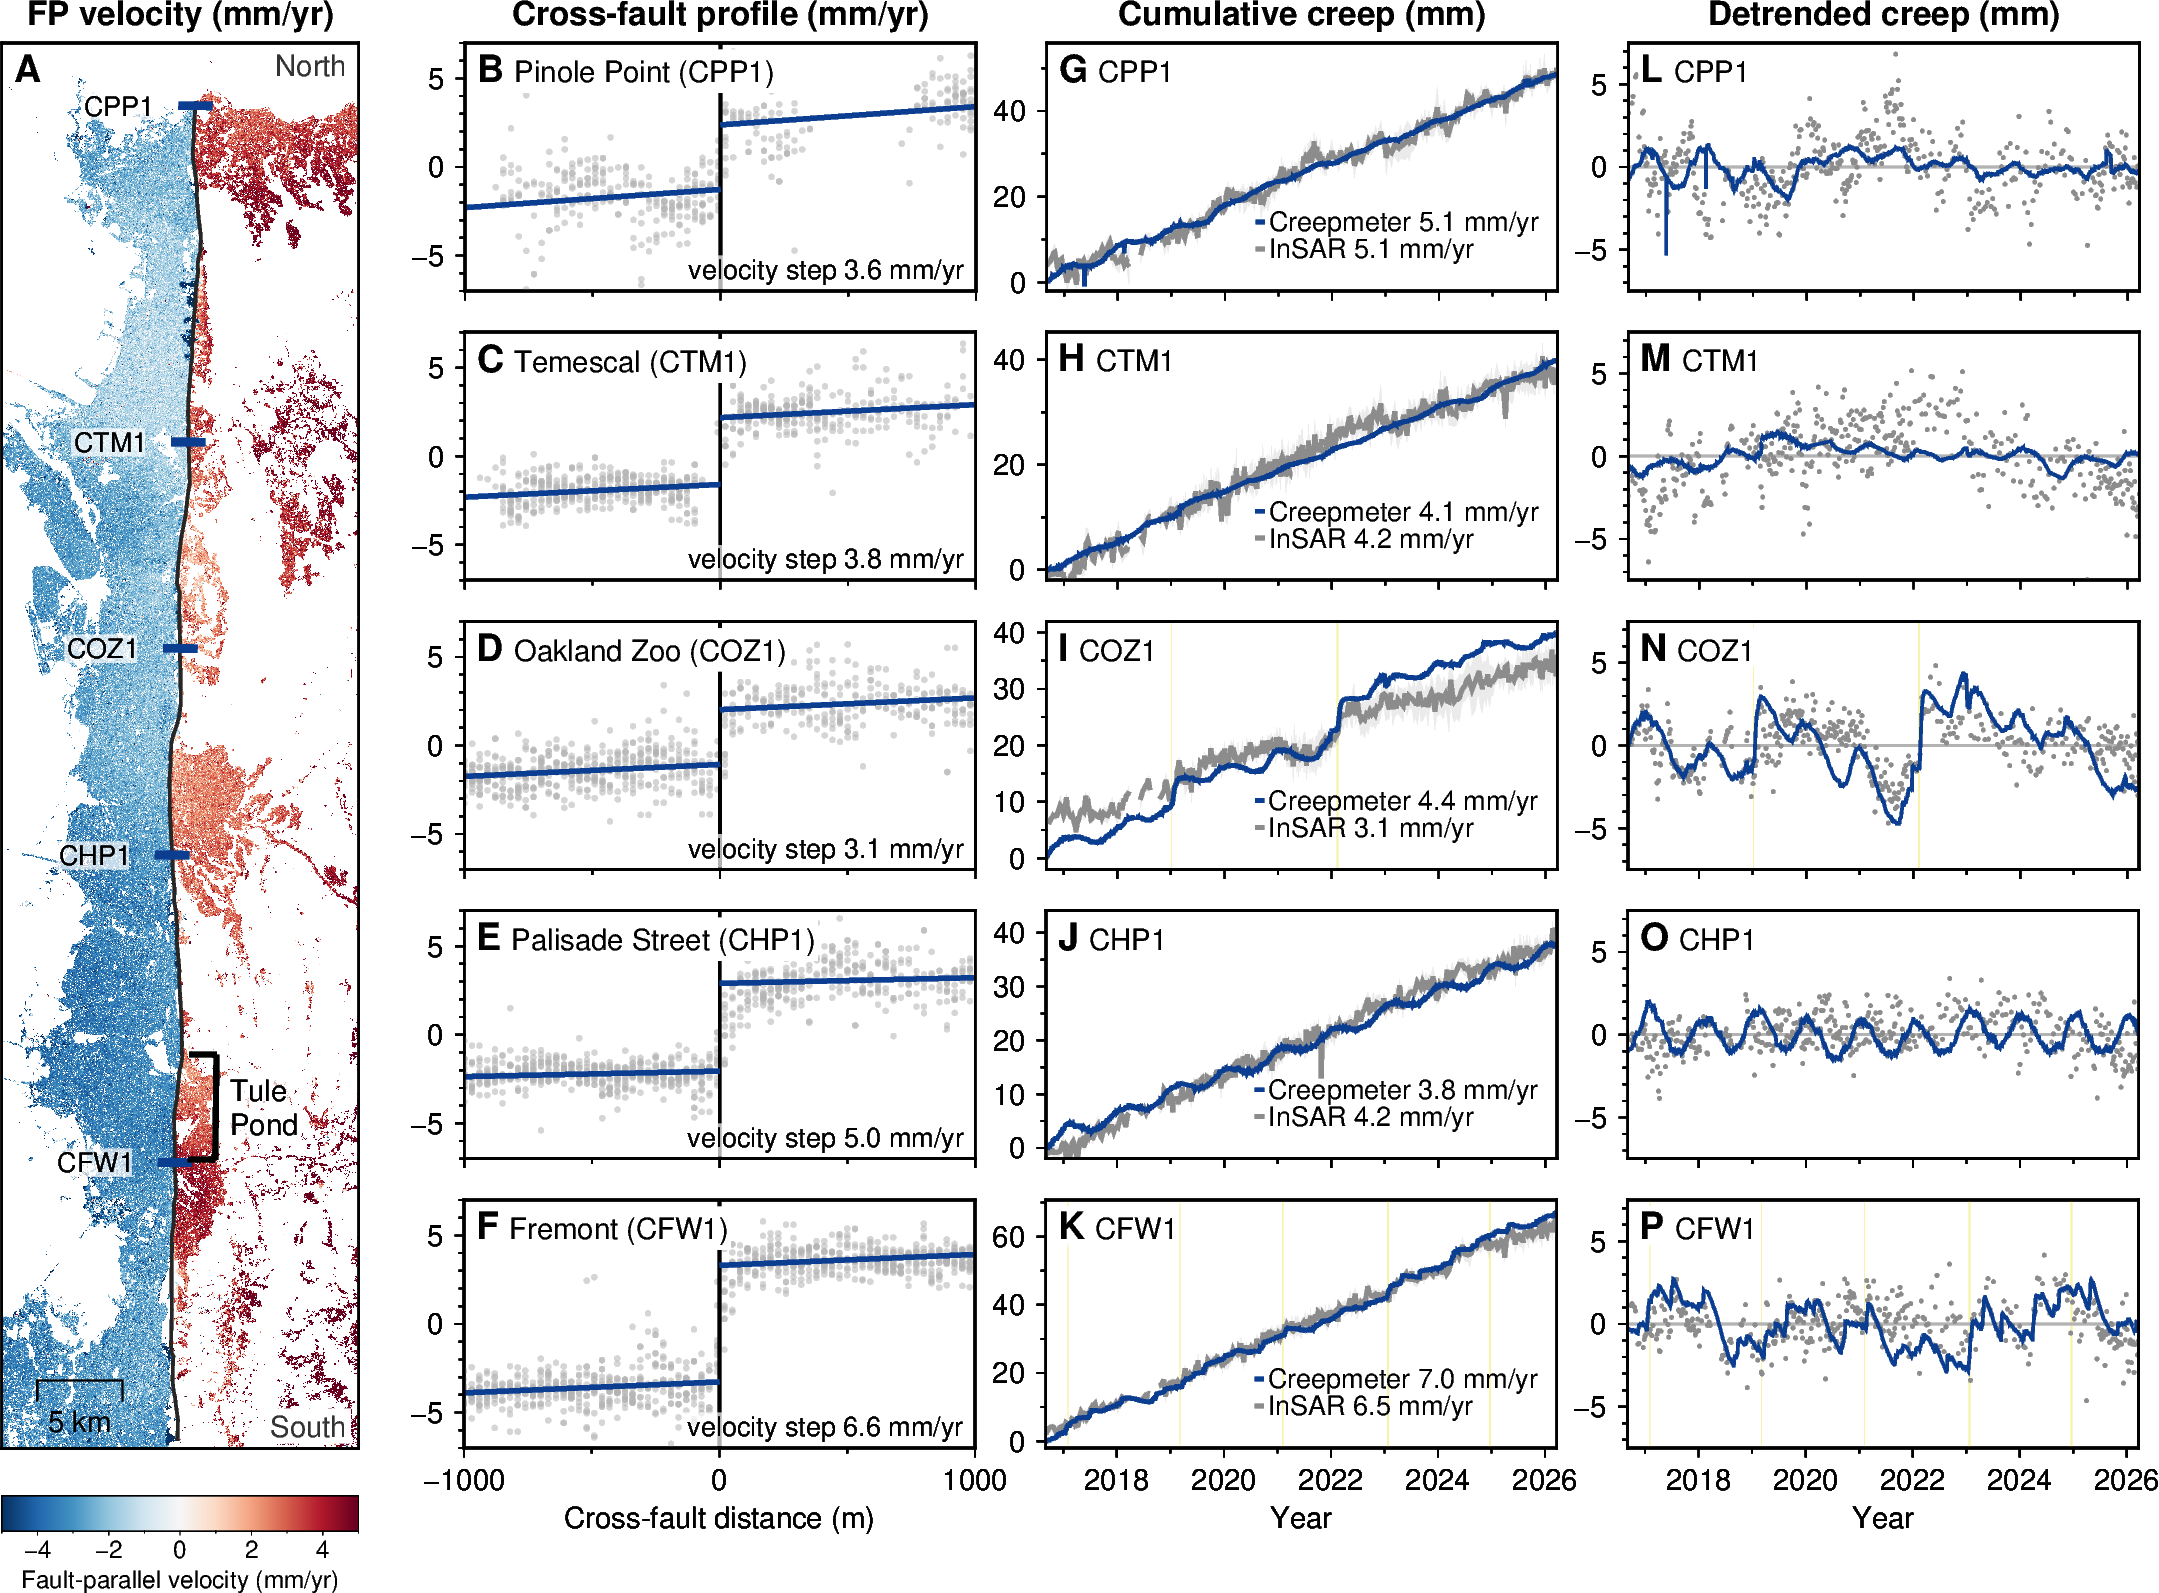

In [7]:
# --- the map in lon/lat for GMT (as notebook 04's Fig 1): the strike-frame rectangle is the region of an
# oblique Mercator whose x axis runs across the fault, so the fault runs up the page with north at the top
from_utm = pyproj.Transformer.from_crs(int(attrs["EPSG"]), 4326, always_xy=True)


def uv_to_lonlat(u, v):
    """Inverse of to_uv: strike-frame km (u along, v across) -> lon/lat, for the corners, the ticks and the bracket."""
    u, v = np.asarray(u, float) * 1e3 + u_pin, np.asarray(v, float) * 1e3 + v0
    return from_utm.transform(v * pe + u * ae, v * pn + u * an)


def gmt_map_size(region, projection):
    """Width and height (cm) GMT gives a region/projection pair (mapproject -W), so panels can be aligned to it."""
    with pygmt.clib.Session() as lib:
        f_ = os.path.join(cpt_dir, "dims.txt")
        lib.call_module("mapproject", f"-R{region} -J{projection} -W ->{f_}")
    return tuple(float(x) for x in open(f_).read().split())


def runs(mask):
    """(start, stop) index pairs of the contiguous True runs of a boolean mask, so a gappy series plots with gaps."""
    idx = np.flatnonzero(np.diff(np.r_[False, np.asarray(mask, bool), False]))
    return list(zip(idx[::2], idx[1::2]))


u_n, u_s = float(ug[0]), float(ug[-1])                                          # the same extent as ob_z
lon_ll, lat_ll = uv_to_lonlat(u_s, -map_half_km)                                # lower-left = south end, west side
lon_ur, lat_ur = uv_to_lonlat(u_n, map_half_km)                                 # upper-right = north end, east side
lon_c, lat_c = uv_to_lonlat(0.5 * (u_s + u_n), 0.0)
corners = np.array([uv_to_lonlat(u_, v_) for u_, v_ in ((u_s, -map_half_km), (u_s, map_half_km), (u_n, map_half_km), (u_n, -map_half_km))])
lat_g = np.arange(corners[:, 1].min() - 0.01, corners[:, 1].max() + 0.01, 0.00028)
lon_g = np.arange(corners[:, 0].min() - 0.01, corners[:, 0].max() + 0.01, 0.00035)
LON, LAT = np.meshgrid(lon_g, lat_g)
Eg, Ng = utm.transform(LON, LAT)
cig = np.round((Eg - x0) / dx).astype(int); rig = np.round((Ng - y0) / dy).astype(int)
okg = (cig >= 0) & (cig < fp_map.shape[1]) & (rig >= 0) & (rig < fp_map.shape[0])
zg = np.full(LON.shape, np.nan); zg[okg] = fp_map[rig[okg], cig[okg]] - ref_mean
grid_ll = xr.DataArray(zg, coords={"lat": lat_g, "lon": lon_g}, dims=("lat", "lon"))
tv, tu = to_uv(prof["ft_lon"].values, prof["ft_lat"].values)

# --- the figure: sizes in cm, one font, 18.3 cm wide (Science full page width)
W_fig = 18.1          # page width before crop; the label overhang brings it to <= 18.3 cm
Hr, gap_row = 2.1, 0.35                 # one row per creepmeter; the interior rows carry no x annotation
Hm = 5 * Hr + 4 * gap_row               # the map spans the five rows (~12 cm); its width follows at true scale (~3.2 cm)
gap_map, gap_col, cb_w = 0.9, 0.6, 2.5
cpt_dir = os.path.join(out_dir, "cpt"); os.makedirs(cpt_dir, exist_ok=True)
cpt_vel = utils.write_cpt(os.path.join(cpt_dir, "fp_rdbu.cpt"), "RdBu_r", -fp_clim, fp_clim)
letters = ("BCDEF", "GHIJK", "LMNOP")

fig = pygmt.Figure()
pygmt.config(FONT="8p,Helvetica", FONT_ANNOT_PRIMARY="7p,Helvetica", FONT_LABEL="7p,Helvetica", MAP_FRAME_TYPE="plain",
             MAP_FRAME_PEN="0.6p", MAP_TICK_LENGTH_PRIMARY="2p", MAP_LABEL_OFFSET="4p", MAP_ANNOT_OFFSET="3p")

# A) the map: oblique Mercator, fault up the page, everything plotted in lon/lat
region_map = f"{lon_ll}/{lat_ll}/{lon_ur}/{lat_ur}+r"
Wm = 3.0
w_, h_ = gmt_map_size(region_map, f"Oa{lon_c}/{lat_c}/{strike - 90}/{Wm}c")
Wm = Wm * Hm / h_                                                 # width that makes the map exactly Hm tall (true scale)
proj_map = f"Oa{lon_c}/{lat_c}/{strike - 90}/{Wm:.3f}c"
Wp = Wc = Wd = (W_fig - Wm - gap_map - 2 * gap_col) / 3.0          # the three columns share the rest of the width
print(f"map panel {Wm:.2f} x {Hm:.2f} cm at true scale; data panels {Wp:.2f} x {Hr:.2f} cm; figure {W_fig} cm wide")
print(f"  map region {region_map}; trial 4.5 cm wide -> GMT {w_:.2f} x {h_:.2f} cm")
assert 2.0 < Wm < 5.0, f"map width {Wm:.2f} cm is off (expect ~3 cm at true scale): region/projection changed?"
fig.basemap(region=region_map, projection=proj_map, frame=["lrtb"])
fig.grdimage(grid=grid_ll, cmap=cpt_vel, nan_transparent=True)
fig.plot(x=prof["ft_lon"].values, y=prof["ft_lat"].values, pen="0.8p,gray15")
for code, la, lo, name in creepmeters:
    cv, cu = to_uv(lo, la)
    kx, ky = uv_to_lonlat([cu, cu], [cv - 1.0, cv + 1.0])                       # a 2 km tick across the fault
    fig.plot(x=kx, y=ky, pen=f"2p,{cm_blue}")
    utils.text_backed(fig, x=lo, y=la, text=code, justify="RM", offset="-0.35c/0c", font="6.5p,Helvetica,black", clearance="0.03c")
for name, (la_lo, la_hi) in seg_ext.items():                      # east of the trace, ticks toward it, label boxed
    jj = [int(np.argmin(np.abs(prof["ft_lat"].values - la))) for la in (la_lo, la_hi)]
    b_lo, b_hi = sorted(float(tu[j]) for j in jj)
    in_b = (tu >= b_lo) & (tu <= b_hi)
    bv = float(np.max(tv[in_b])) + 2.0 if in_b.any() else float(max(tv[j] for j in jj)) + 2.0
    bx, by = uv_to_lonlat([b_lo, b_hi], [bv, bv]); fig.plot(x=bx, y=by, pen="1.4p,black")
    for u_ in (b_lo, b_hi):
        bx, by = uv_to_lonlat([u_, u_], [bv - 1.6, bv]); fig.plot(x=bx, y=by, pen="1.4p,black")
    u_mid = 0.5 * (b_lo + b_hi)                                   # two rows (GMT has no newline outside paragraph mode)
    lx, ly = uv_to_lonlat([u_mid - 1.0, u_mid + 1.0], [bv, bv])
    utils.text_backed(fig, x=lx, y=ly, text=name.split(), justify="LM", offset="0.12c/0c", font="7p,Helvetica,black", clearance="0.03c")
fig.text(position="TR", text="North", offset="-0.1c/-0.1c", font="7p,Helvetica,gray20", fill="white", clearance="0.05c")
fig.text(position="BR", text="South", offset="-0.1c/0.1c", font="7p,Helvetica,gray20", fill="white", clearance="0.05c")
fig.text(position="TL", text="@%Helvetica-Bold%A@%%", offset="0.1c/-0.1c", font="9p,Helvetica", fill="white", clearance="0.04c")
fig.text(position="TC", text="FP velocity (mm/yr)", justify="BC", offset="0c/0.15c", font="8p,Helvetica-Bold", no_clip=True)
fig.basemap(region=region_map, projection=proj_map, frame=["lrtb"], map_scale="jBL+w5k+o0.3c/0.4c")       # frame on top, scale bar
with pygmt.config(FONT_ANNOT_PRIMARY="13p", FONT_LABEL="13p"):     # GMT scales colour-bar text down with the bar thickness (-> ~6.5p)
    # bar as wide as the map, so the bar and its label are both centred under the map (as Fig 1 reads)
    fig.colorbar(cmap=cpt_vel, position=f"x0c/-0.4c+w{Wm:.2f}c/0.3c+h+jTL", frame="xa2f1+lFault-parallel velocity (mm/yr)")

# B-P) five rows, north to south: profile, cumulative, detrended
fig.shift_origin(xshift=f"{Wm + gap_map}c", yshift=f"{Hm - Hr}c")
titles = ("Cross-fault profile (mm/yr)", "Cumulative creep (mm)", "Detrended creep (mm)")
for i, (code, la, lo, name) in enumerate(creepmeters):
    r = df.loc[code]
    ct, ccum = cm_data[code]
    last = i == len(creepmeters) - 1
    ev_rows = row_events.get(code, pd.DataFrame())
    # col 2: cross-fault velocity profile with the step
    s = xf[(xf["code"] == code) & (xf["dist_m"].abs() <= max_dist_m)]
    d = s["dist_m"].values.astype(float); v = s["fp_vel"].values.astype(float); v = v - v.mean()
    G = np.column_stack([np.ones_like(d), d, (d > 0).astype(float)])
    a_, b_, step_mm = np.linalg.lstsq(G, v, rcond=None)[0]
    xw, xe = np.array([-max_dist_m, 0.0]), np.array([0.0, max_dist_m])
    region_p = [-max_dist_m, max_dist_m, -prof_ylim, prof_ylim]
    frame_p = ["WSrt" if last else "Wsrt", "xa1000f500+lCross-fault distance (m)" if last else "xa1000f500", "ya5f1"]
    fig.basemap(region=region_p, projection=f"X{Wp}c/{Hr}c", frame=frame_p)
    fig.plot(x=d, y=v, style="c0.05c", fill="gray70@45")
    fig.plot(x=[0, 0], y=[-prof_ylim, prof_ylim], pen="0.8p,black")
    fig.plot(x=xw, y=a_ + b_ * xw, pen=f"1.2p,{cm_blue}"); fig.plot(x=xe, y=a_ + b_ * xe + step_mm, pen=f"1.2p,{cm_blue}")
    utils.text_backed(fig, position="BR", text=f"velocity step {step_mm:.1f} mm/yr", offset="-0.1c/0.1c", font="6.5p,Helvetica", clearance="0.03c")
    fig.text(position="TL", text=f"@%Helvetica-Bold%{letters[0][i]}@%% @:7p:{name} ({code})@::", offset="0.1c/-0.1c", font="9p,Helvetica", fill="white", clearance="0.04c")
    if i == 0:
        fig.text(position="TC", text=titles[0], justify="BC", offset="0c/0.15c", font="8p,Helvetica-Bold", no_clip=True)
    fig.basemap(region=region_p, projection=f"X{Wp}c/{Hr}c", frame=frame_p)      # frame on top: a clean edge
    # col 3: cumulative creep
    fig.shift_origin(xshift=f"{Wp + gap_col}c")
    t, mean, std, _n = stack_insar(fp_ts, la)
    mok = np.isfinite(mean)
    cm_at_t = np.interp(t[mok], ct, ccum)
    mean_disp = mean + float(np.mean(cm_at_t - mean[mok]))     # display alignment only; the rate is untouched
    ymax = 1.05 * max(float(np.nanmax(ccum)), float(np.nanmax(mean_disp + std)))
    region_c = [t0, t1, -2.0, ymax]
    ya_c = 20 if ymax > 45 else 10
    frame_c = ["WSrt" if last else "Wsrt", "xa2f1+lYear" if last else "xa2f1", f"ya{ya_c}f{ya_c / 2:g}"]
    fig.basemap(region=region_c, projection=f"X{Wc}c/{Hr}c", frame=frame_c)
    for _, ev in ev_rows.iterrows():
        e0, e1 = ev["onset_lo"], ev["onset_hi"]                  # the InSAR detection interval; the tail is used in the statistics only
        fig.plot(x=[e0, e1, e1, e0], y=[region_c[2], region_c[2], region_c[3], region_c[3]], fill=gold + "@55", close=True)
    for a0, a1 in runs(mok):                                   # the InSAR stack has gaps: one envelope piece per run
        if a1 - a0 >= 2:
            fig.plot(x=np.r_[t[a0:a1], t[a0:a1][::-1]], y=np.r_[(mean_disp + std)[a0:a1], (mean_disp - std)[a0:a1][::-1]],
                     fill="gray@70", close=True)
    # legend order creepmeter then InSAR, creepmeter drawn on top: its legend entry comes from an off-region (clipped) stub
    fig.plot(x=[t0 - 10, t0 - 9], y=[0, 0], pen=f"1.0p,{cm_blue}", label=f"Creepmeter {r.cm_rate:.1f} mm/yr")
    for k_, (a0, a1) in enumerate(runs(mok)):
        fig.plot(x=t[a0:a1], y=mean_disp[a0:a1], pen=f"1.1p,{insar_grey}", label=f"InSAR {r.cr_rate:.1f} mm/yr" if k_ == 0 else None)
    fig.plot(x=ct, y=ccum, pen=f"1.0p,{cm_blue}")
    # legend inside the data: 6.5p text, but no excess white space (fixed narrow width, short symbol column,
    # tight line spacing, box clearance 0.05 cm)
    with pygmt.config(FONT_ANNOT_PRIMARY="6.5p"):
        fig.legend(position="JBR+jBR+o0.1c/0.1c+w2.6c+l1.0", box=False, S="0.25c")   # box just wide enough for the text, 0.1 cm off the corner     # translucent box: readable where the lines pass behind
    fig.text(position="TL", text=f"@%Helvetica-Bold%{letters[1][i]}@%% @:7p:{code}@::", offset="0.1c/-0.1c", font="9p,Helvetica", fill="white", clearance="0.04c")
    if i == 0:
        fig.text(position="TC", text=titles[1], justify="BC", offset="0c/0.15c", font="8p,Helvetica-Bold", no_clip=True)
    fig.basemap(region=region_c, projection=f"X{Wc}c/{Hr}c", frame=frame_c)
    # col 4: detrended
    fig.shift_origin(xshift=f"{Wc + gap_col}c")
    region_d = [t0, t1, -fp_clim * 1.5, fp_clim * 1.5]
    frame_d = ["WSrt" if last else "Wsrt", "xa2f1+lYear" if last else "xa2f1", "ya5f1"]
    fig.basemap(region=region_d, projection=f"X{Wd}c/{Hr}c", frame=frame_d)
    for _, ev in ev_rows.iterrows():
        e0, e1 = ev["onset_lo"], ev["onset_hi"]                  # the InSAR detection interval; the tail is used in the statistics only
        fig.plot(x=[e0, e1, e1, e0], y=[region_d[2], region_d[2], region_d[3], region_d[3]], fill=gold + "@55", close=True)
    fig.plot(x=[t0, t1], y=[0, 0], pen="0.6p,gray70")
    dmean = utils.detrend(t, mean); dok = np.isfinite(dmean)
    fig.plot(x=t[dok], y=dmean[dok], style="c0.04c", fill=insar_grey)
    fig.plot(x=ct, y=utils.detrend(ct, ccum), pen=f"0.8p,{cm_blue}")
    fig.text(position="TL", text=f"@%Helvetica-Bold%{letters[2][i]}@%% @:7p:{code}@::", offset="0.1c/-0.1c", font="9p,Helvetica", fill="white", clearance="0.04c")
    if i == 0:
        fig.text(position="TC", text=titles[2], justify="BC", offset="0c/0.15c", font="8p,Helvetica-Bold", no_clip=True)
    fig.basemap(region=region_d, projection=f"X{Wd}c/{Hr}c", frame=frame_d)
    if not last:                                               # back to column 2, one row down
        fig.shift_origin(xshift=f"-{Wp + Wc + 2 * gap_col}c", yshift=f"-{Hr + gap_row}c")

fig_val = os.path.join(fig_dir, f"figS_validation_cohmap{coh_velocity:g}_{params}_profile{max_dist_m:.0f}m_stack{stack_max}x{stack_km * 1000:.0f}m.png")
fig.savefig(fig_val, dpi=300, transparent=False, crop="+gwhite", anti_alias=True, show=False)
fig.savefig(fig_val.replace(".png", ".pdf"), transparent=False, crop="+gwhite", anti_alias=True, show=False)
print("Saved figure to:", fig_val)

fig.show()

## The aperture ladder, from the frozen sweep

Every cross-fault bin that was scored, re-scored here on one FIXED stack
(4 rows within 0.4 km of each creepmeter, no widening) so the bins are
comparable: the five-station rate RMS (long-term agreement), the fraction of
the trace with data (completeness), and at COZ1 the detrended correlation
(event shape) and the fraction of the creepmeter's two event steps
recovered (event amplitude). Bins reaching the trace agree worst on rate
(the phase-linking smoothing dilutes the step over ~55 to 65 m) but best on
event shape; the 30 to 150 m bin is the compromise carried forward.

In [8]:
def event_step(t, cum, s, e):
    """Slip across one event window against the local inter-event trend
    (fit on the collars either side, never inside), mean residual after minus before."""
    pre = (t >= s - collar_yr) & (t < s); post = (t > e) & (t <= e + collar_yr)
    if pre.sum() < 5 or post.sum() < 5:
        return np.nan
    fit = np.isfinite(cum) & (pre | post)
    if fit.sum() < 12:
        return np.nan
    rres = cum - np.polyval(np.polyfit(t[fit], cum[fit], 1), t)
    return float(np.nanmean(rres[post]) - np.nanmean(rres[pre]))


def load_fp(cdir):
    fp = pd.read_csv(os.path.join(cdir, "fp_ts.csv"), index_col=0)
    fp.columns = fp.columns.astype(float); fp.index = fp.index.astype(float)
    return fp


coz1_lat = [la for c, la, lo, n in creepmeters if c == "COZ1"][0]
ladder_rows = []
for setname, bins in (("fixed", fixed_width), ("growing", [b for b in growing if b not in fixed_width]),
                      ("original", original), ("inner", [b for b in inner_edge if b not in fixed_width + growing + original])):
    for inner, outer in bins:
        tag = f"ap{inner}-{outer}m_coh{ladder_coh:g}_mp{min_points}"
        cdir = os.path.join(common_paths["sweep_dir"], tag)
        if not os.path.isdir(cdir):
            print(f"  missing, skipped: {tag}")
            continue
        fp = load_fp(cdir)
        # rate RMS over the stations where the fixed stack can be formed
        d_cross = []
        for code, la, lo, name in creepmeters:
            st = stack_insar(fp, la, half_km=ladder_stack_km, n_stack=ladder_n_stack, exact=True)
            if st is None:
                continue
            t, mean, _, _ = st; ok = np.isfinite(mean)
            ct, ccum = cm_data[code]
            d_cross.append(np.polyfit(t[ok], mean[ok], 1)[0] - np.polyfit(ct, ccum, 1)[0])
        # COZ1: detrended correlation and step fraction
        st = stack_insar(fp, coz1_lat, half_km=ladder_stack_km, n_stack=ladder_n_stack, exact=True)
        det_r = frac = resid_sd = np.nan
        if st is not None:
            t, mean, _, _ = st; ok = np.isfinite(mean); ti, ins = t[ok], mean[ok]
            ct, ccum = cm_data["COZ1"]; cmi = np.interp(ti, ct, ccum)
            di, dc = utils.detrend(ti, ins), utils.detrend(ti, cmi); gd = np.isfinite(di) & np.isfinite(dc)
            det_r = float(np.corrcoef(di[gd], dc[gd])[0, 1])
            si = np.array([event_step(ti, ins, a, b) for a, b in coz1_events]); sc = np.array([event_step(ti, cmi, a, b) for a, b in coz1_events])
            g = np.isfinite(si) & np.isfinite(sc) & (sc > 0)
            frac = float(np.sum(si[g]) / np.sum(sc[g])) if g.any() else np.nan
            A = np.c_[np.ones(ok.sum()), ti - ti.mean(), np.sin(2 * np.pi * ti), np.cos(2 * np.pi * ti)]
            resid_sd = float(np.std(ins - A @ np.linalg.lstsq(A, ins, rcond=None)[0]))
        ladder_rows.append(dict(set=setname, tag=tag, inner=inner, outer=outer, centre=(inner + outer) / 2, width=outer - inner,
                                n_stations=len(d_cross), valid=100.0 * fp.shape[0] / len(prof),
                                rate_rms=float(np.sqrt(np.mean(np.square(d_cross)))) if d_cross else np.nan,
                                coz1_det_r=det_r, coz1_step_frac=frac, coz1_resid_sd_mm=resid_sd))
ladder = pd.DataFrame(ladder_rows)
ladder.to_csv(os.path.join(out_dir, "sweep_ladder_scores.csv"), index=False)
print(ladder.drop(columns=["tag"]).round(3).to_string(index=False))
sel = ladder[(ladder.inner == selected[0]) & (ladder.outer == selected[1])].iloc[0]
print("")
print(f"selected bin {selected[0]}-{selected[1]} m at coherence {ladder_coh}: rate RMS {sel.rate_rms:.2f} mm/yr on {sel.n_stations} stations, "
      f"{sel.valid:.0f}% of the trace, COZ1 det r {sel.coz1_det_r:.2f}, step recovered {100 * sel.coz1_step_frac:.0f}%")

# the chosen bin at the three coherence thresholds (the sweep's own summary table):
# the threshold is second order for the rate and the paper runs at 0.7 for coverage
sw = pd.read_csv(os.path.join(common_paths["sweep_dir"], "sweep_summary_mp5.csv"))
sw = sw[sw.tag.str.startswith(f"ap{selected[0]}-{selected[1]}m")].sort_values("coh")
coh_rows = []
for _, r_ in sw.iterrows():
    fpc = load_fp(os.path.join(common_paths["sweep_dir"], r_.tag))
    coh_rows.append(dict(coh=r_.coh, rate_rms=r_.rate_rms, rate_bias=r_.rate_bias, n_crossings=fpc.shape[0]))
coh_tab = pd.DataFrame(coh_rows)
print(coh_tab.round(3).to_string(index=False))

     set  inner  outer  centre  width  n_stations  valid  rate_rms  coz1_det_r  coz1_step_frac  coz1_resid_sd_mm
   fixed      0    100    50.0    100           4 54.614     1.093       0.602           0.376             1.500
   fixed     50    150   100.0    100           5 59.039     0.605       0.512           0.393             1.696
   fixed    100    200   150.0    100           4 61.820     0.714       0.476           0.600             1.784
   fixed    150    250   200.0    100           4 58.534     0.651       0.477           0.599             1.974
   fixed    200    300   250.0    100           4 57.269     0.799       0.345           0.766             2.252
   fixed    300    400   350.0    100           4 54.235     0.837       0.196           0.223             2.344
   fixed    400    500   450.0    100           4 53.982     1.032       0.308           0.538             2.632
 growing    100    300   200.0    200           4 69.659     0.741       0.418           0.622  

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


Saved figure to: /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-09-30/figS_binning_ladder_coh0.9_mp5_stack4x0.4km.png


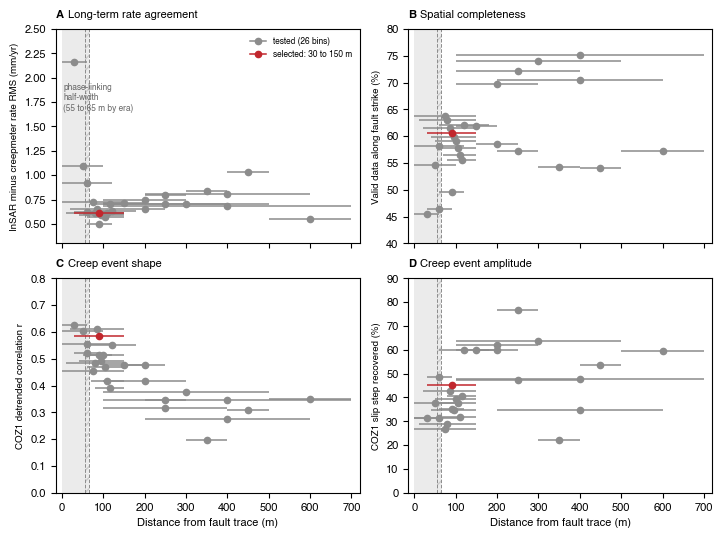

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.4), sharex=True)
axes = axes.ravel()
ordered = ladder.assign(_z=[(r.inner, r.outer) == selected for r in ladder.itertuples()]).sort_values("_z")


def panel_label(ax, letter, text, x=0.025, y=0.95, size=8.5):
    """Science style: bold capital, then the description in normal weight, one translucent box behind both."""
    # one wide box behind both pieces: drawn first on an invisible copy of the full string, then the two texts on top
    ax.text(x, y, f"{letter} {text}", transform=ax.transAxes, va="top", ha="left", fontsize=size, alpha=0,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7), zorder=5)
    t = ax.text(x, y, letter, transform=ax.transAxes, va="top", ha="left", fontsize=size, fontweight="bold", zorder=6)
    ax.annotate(text, xy=(1, 1), xycoords=t, xytext=(3, 0), textcoords="offset points", va="top", ha="left",
                fontsize=size, zorder=6)


def draw(ax, col, scale=1.0):
    for _, r in ordered.iterrows():
        if not np.isfinite(r[col]):
            continue
        y = scale * r[col]; sel_ = (r.inner, r.outer) == selected
        c, z = ("#C1272D", 6) if sel_ else ("0.55", 2)
        ax.plot([r.inner, r.outer], [y, y], "-", color=c, lw=1.1, zorder=z, solid_capstyle="butt")
        ax.plot(r.centre, y, "o", ms=4.5, color=c, zorder=z + 1)


for ax in axes:
    ax.axvspan(0, kernel_m[0], facecolor="0.92", zorder=0)
    ax.axvspan(*kernel_m, facecolor="0.92", zorder=0, hatch="///", edgecolor="0.80", lw=0)
    for k in kernel_m:
        ax.axvline(k, color="0.55", lw=0.7, ls="--", zorder=1)
    ax.set_xlim(-15, 720)
axes[0].text(3, 1.95, "phase-linking\nhalf-width\n(55 to 65 m by era)", fontsize=6, color="0.40", va="top")
for ax, col, ylab, ylim, title, scale in ((axes[0], "rate_rms", "InSAR minus creepmeter rate RMS (mm/yr)", (0.3, 2.5), "A Long-term rate agreement", 1),
                                          (axes[1], "valid", "Valid data along fault strike (%)", (40, 80), "B Spatial completeness", 1),
                                          (axes[2], "coz1_det_r", "COZ1 detrended correlation r", (0, 0.8), "C Creep event shape", 1),
                                          (axes[3], "coz1_step_frac", "COZ1 slip step recovered (%)", (0, 90), "D Creep event amplitude", 100)):
    draw(ax, col, scale); ax.set_ylabel(ylab, fontsize=7); ax.set_ylim(*ylim)
    letter_, text_ = title.split(" ", 1)
    panel_label(ax, letter_, text_, x=0.0, y=1.09, size=8)
for ax in axes[2:]:
    ax.set_xlabel("Distance from fault trace (m)")
axes[0].legend(handles=[Line2D([], [], color="0.55", lw=1.1, marker="o", ms=4.5, label=f"tested ({len(ladder)} bins)"),
                        Line2D([], [], color="#C1272D", lw=1.1, marker="o", ms=4.5, label=f"selected: {selected[0]} to {selected[1]} m")],
               fontsize=6, loc="upper right")
fig.tight_layout()
fig_lad = os.path.join(fig_dir, f"figS_binning_ladder_coh{ladder_coh:g}_mp{min_points}_stack{ladder_n_stack}x{ladder_stack_km}km.png")
fig.savefig(fig_lad, dpi=300); fig.savefig(fig_lad.replace(".png", ".pdf"))
print("Saved figure to:", fig_lad)
plt.show()

## REGISTER

In [10]:
L += ["", f"APERTURE LADDER (frozen sweep at coherence {ladder_coh}, fixed 4-row stack within 0.4 km)",
      ladder.drop(columns=["tag"]).round(3).to_string(index=False), "",
      f"chosen bin {selected[0]}-{selected[1]} m by coherence threshold:", coh_tab.round(3).to_string(index=False)]
sidecar = REG.sidecar("05_validation", L)
for c, r in df.iterrows():
    for key, lab in (("cm", "creepmeter"), ("cr", "crossing"), ("st", "step")):
        REG.register(f"05_{c}_{lab}_rate_mm_yr", r[f"{key}_rate"], "mm/yr", 2, where="M4, Fig S validation", cell="bootstrap", sidecar=sidecar)
        REG.register(f"05_{c}_{lab}_ci_lo", r[f"{key}_lo"], "mm/yr", 2, where="M4", cell="bootstrap", sidecar=sidecar)
        REG.register(f"05_{c}_{lab}_ci_hi", r[f"{key}_hi"], "mm/yr", 2, where="M4", cell="bootstrap", sidecar=sidecar)
    REG.register(f"05_{c}_det_r", r.det_r, "1", 2, where="M4", cell="bootstrap", sidecar=sidecar)
    REG.register(f"05_{c}_det_rmse_mm", r.det_rmse, "mm", 2, where="M4", cell="bootstrap", sidecar=sidecar)
REG.register("05_rate_rms_mm_yr", agr["cross"]["rms"], "mm/yr", 2, where="P2, M4", cell="agreement", sidecar=sidecar)
REG.register("05_rate_bias_mm_yr", agr["cross"]["bias"], "mm/yr", 2, where="M4", cell="agreement", sidecar=sidecar)
REG.register("05_rate_maxabs_mm_yr", agr["cross"]["maxabs"], "mm/yr", 2, where="M4", cell="agreement", sidecar=sidecar)
REG.register("05_rate_rms_excl_coz1_mm_yr", agr["cross_excl_coz1"]["rms"], "mm/yr", 2, where="M4", cell="agreement", sidecar=sidecar)
REG.register("05_step_rms_mm_yr", agr["step"]["rms"], "mm/yr", 2, where="M4", cell="agreement", sidecar=sidecar)
REG.register("05_step_bias_mm_yr", agr["step"]["bias"], "mm/yr", 2, where="M4", cell="agreement", sidecar=sidecar)
REG.register("05_noise_floor_det_rmse_mm", floor_rmse, "mm", 2, where="P2, M4", cell="noise-floor", sidecar=sidecar)
for _, r_ in cfw_win.iterrows():
    tag = f"{r_.onset_yr:.2f}".replace(".", "p")
    REG.register(f"05_cfw1_win_{tag}_mm", r_.slip_win_mm, "mm", 2, where="P3, Fig S validation", cell="cfw1-windows", sidecar=sidecar)
    REG.register(f"05_cfw1_win_{tag}_expected_mm", r_.expect_win_mm, "mm", 2, where="P3", cell="cfw1-windows", sidecar=sidecar)
    REG.register(f"05_cfw1_win_{tag}_data_pct", r_.cover_pct, "%", 0, where="P3", cell="cfw1-windows", sidecar=sidecar)
REG.register("05_det_rmse_min_mm", df.det_rmse.min(), "mm", 2, where="M4", cell="noise-floor", sidecar=sidecar)
REG.register("05_det_rmse_max_mm", df.det_rmse.max(), "mm", 2, where="M4", cell="noise-floor", sidecar=sidecar)
REG.register("05_noise_floor_steady_std_mm", floor_run10, "mm", 2, where="M4 (alternative definition)", cell="noise-floor", sidecar=sidecar)
for _, r_ in coh_tab.iterrows():
    REG.register(f"05_coh{r_.coh:g}_rate_rms_mm_yr", r_.rate_rms, "mm/yr", 2, where="M3", cell="ladder", sidecar=sidecar)
    REG.register(f"05_coh{r_.coh:g}_n_crossings", int(r_.n_crossings), "count", 0, where="M3", cell="ladder", sidecar=sidecar)
REG.register("05_ladder_n_bins", len(ladder), "count", 0, where="M3, Fig S ladder", cell="ladder", sidecar=sidecar)
REG.register("05_ladder_selected_rate_rms", sel.rate_rms, "mm/yr", 2, where="M3, Fig S ladder", cell="ladder", sidecar=sidecar)
REG.register("05_ladder_selected_valid_pct", sel.valid, "pct", 0, where="M3, Fig S ladder", cell="ladder", sidecar=sidecar)
REG.register("05_ladder_selected_coz1_det_r", sel.coz1_det_r, "1", 2, where="M3, Fig S ladder", cell="ladder", sidecar=sidecar)
REG.register("05_ladder_selected_coz1_step_pct", 100 * sel.coz1_step_frac, "pct", 0, where="M3, Fig S ladder", cell="ladder", sidecar=sidecar)
REG.render()

Saved stats to: /Users/dlindsay/work/proj_TulePond_DISP/outputs/05_validation/05_validation_stats.txt
  registered 05_CPP1_creepmeter_rate_mm_yr = 5.05 mm/yr  -> M4, Fig S validation


  registered 05_CPP1_creepmeter_ci_lo = 4.95 mm/yr  -> M4
  registered 05_CPP1_creepmeter_ci_hi = 5.14 mm/yr  -> M4
  registered 05_CPP1_crossing_rate_mm_yr = 5.07 mm/yr  -> M4, Fig S validation


  registered 05_CPP1_crossing_ci_lo = 4.81 mm/yr  -> M4
  registered 05_CPP1_crossing_ci_hi = 5.36 mm/yr  -> M4
  registered 05_CPP1_step_rate_mm_yr = 3.65 mm/yr  -> M4, Fig S validation


  registered 05_CPP1_step_ci_lo = 2.48 mm/yr  -> M4
  registered 05_CPP1_step_ci_hi = 4.76 mm/yr  -> M4
  registered 05_CPP1_det_r = 0.27 1  -> M4


  registered 05_CPP1_det_rmse_mm = 1.83 mm  -> M4
  registered 05_CTM1_creepmeter_rate_mm_yr = 4.11 mm/yr  -> M4, Fig S validation


  registered 05_CTM1_creepmeter_ci_lo = 4.02 mm/yr  -> M4
  registered 05_CTM1_creepmeter_ci_hi = 4.21 mm/yr  -> M4
  registered 05_CTM1_crossing_rate_mm_yr = 4.20 mm/yr  -> M4, Fig S validation


... (28 outputs left out)

  registered 05_coh0.9_n_crossings = 480 count  -> M3
  registered 05_ladder_n_bins = 26 count  -> M3, Fig S ladder
  registered 05_ladder_selected_rate_rms = 0.61 mm/yr  -> M3, Fig S ladder


  registered 05_ladder_selected_valid_pct = 61 pct  -> M3, Fig S ladder
  registered 05_ladder_selected_coz1_det_r = 0.58 1  -> M3, Fig S ladder


  registered 05_ladder_selected_coz1_step_pct = 45 pct  -> M3, Fig S ladder
Rendered registry to: /Users/dlindsay/work/proj_TulePond_DISP/outputs/registry.txt


'/Users/dlindsay/work/proj_TulePond_DISP/outputs/registry.txt'